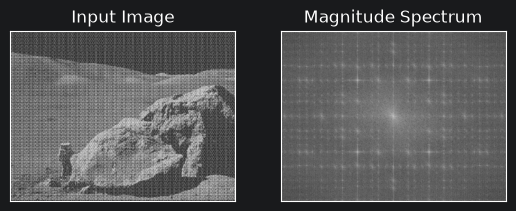

In [18]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
 
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)
 
dft = cv.dft(np.float32(img),flags = cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
 
magnitude_spectrum = 20*np.log(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))
 
plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(magnitude_spectrum, cmap = 'gray')
plt.title('Magnitude Spectrum'), plt.xticks([]), plt.yticks([])
plt.show()

In [19]:
#Filter creating
# Low pass filter
mask = np.zeros((img.shape[0],img.shape[1],2),np.uint8)
centerX, centerY = (int(img.shape[0] / 2),int(img.shape[1] / 2))
mask[centerX-50:centerX+50, centerY - 50:centerY+50,:] = 1

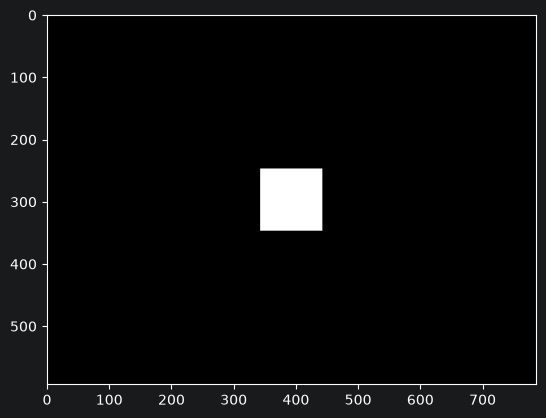

In [20]:
plt.imshow(mask[:,:,0], cmap = 'gray')

In [21]:
# Filtering
dft_shift = dft_shift*mask

C:\Users\roman\AppData\Local\Temp\ipykernel_28864\3830399572.py:1: RuntimeWarning: divide by zero encountered in log
  filtering_magn_res = 20*np.log(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))


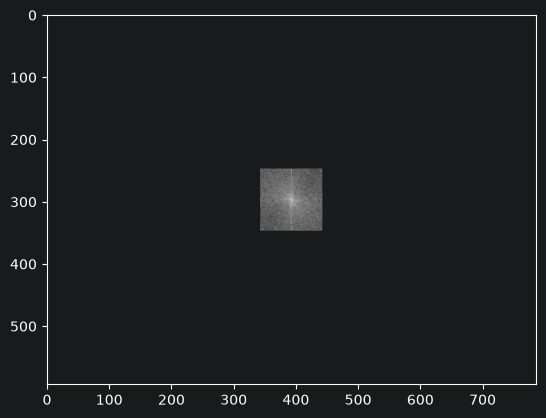

In [22]:
filtering_magn_res = 20*np.log(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))
plt.imshow(filtering_magn_res, cmap='gray')

In [23]:
#fshift = dft_shift*mask
f_ishift = np.fft.ifftshift(dft_shift)
img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:,:,0],img_back[:,:,1])

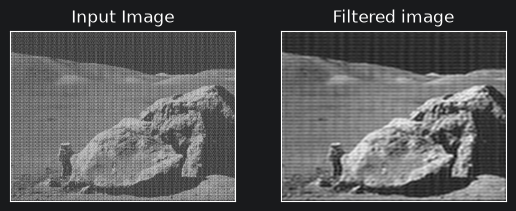

In [24]:
plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(img_back, cmap = 'gray')
plt.title('Filtered image'), plt.xticks([]), plt.yticks([])
plt.show()

In [25]:
# Реализуйте высокочастотную фильтрацию на основе ядра Гаусса
# Реализуйте вычисление свертки с помощью преобразования Фурье
# Реализуйте удаление периодического шума с помощью преобразования Фурье

1 задание

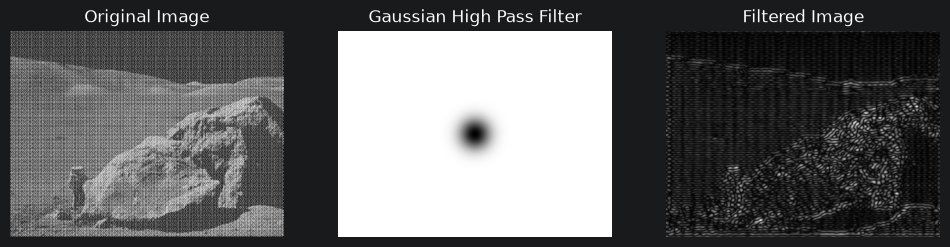

In [26]:


rows, cols = img.shape
center_y, center_x = rows // 2, cols // 2

sigma = 30
y, x = np.ogrid[:rows, :cols]

distance = (x - center_x)**2 + (y - center_y)**2
mask_gauss = 1 - np.exp(-distance / (2 * sigma**2))

dft_gauss = dft_shift * mask_gauss[:, :, np.newaxis]

f_ishift = np.fft.ifftshift(dft_gauss)
img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:, :, 0],
                        img_back[:, :, 1])

plt.figure(figsize=(12, 4))

plt.subplot(131)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(132)
plt.imshow(mask_gauss, cmap='gray')
plt.title('Gaussian High Pass Filter')
plt.axis('off')

plt.subplot(133)
plt.imshow(img_back, cmap='gray')
plt.title('Filtered Image')
plt.axis('off')

plt.show()


2 задание

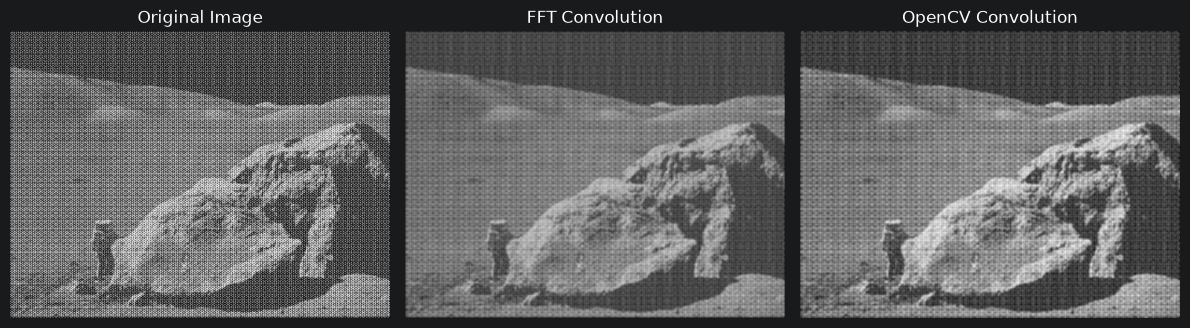

In [27]:

kernel = np.ones((5, 5), np.float32) / 25

rows, cols = img.shape

kernel_padded = np.zeros((rows + 4, cols + 4), np.float32)
kernel_padded[:5, :5] = kernel

img_padded = np.pad(img.astype(np.float32), ((0, 4), (0, 4)))

img_fft = np.fft.fft2(img_padded)
kernel_fft = np.fft.fft2(kernel_padded)

result_fft = np.fft.ifft2(img_fft * kernel_fft).real
result_fft = result_fft[2:rows + 2, 2:cols + 2]

result_cv = cv.filter2D(img, -1, kernel)

plt.figure(figsize=(12, 4))

plt.subplot(131)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(132)
plt.imshow(result_fft, cmap='gray', vmin=0, vmax=255)
plt.title('FFT Convolution')
plt.axis('off')

plt.subplot(133)
plt.imshow(result_cv, cmap='gray')
plt.title('OpenCV Convolution')
plt.axis('off')

plt.tight_layout()
plt.show()


3 задание

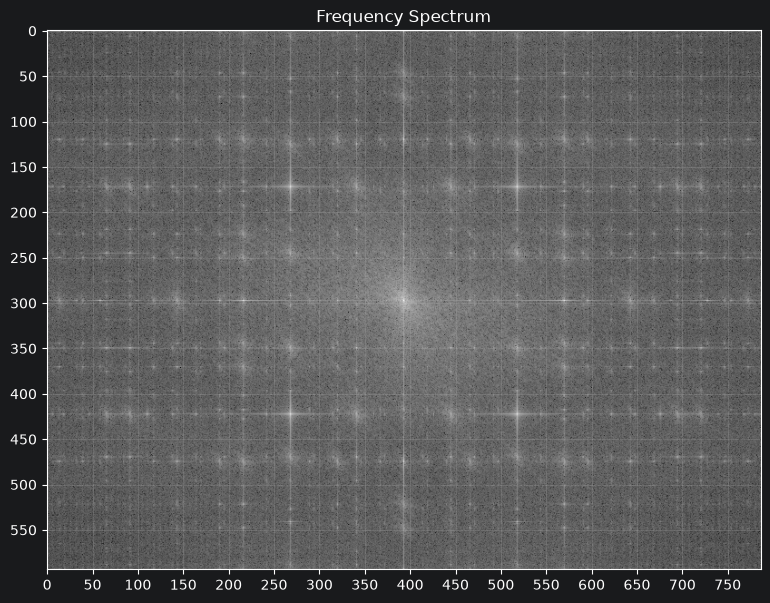

In [28]:

fft = np.fft.fftshift(np.fft.fft2(img.astype(np.float32)))
spectrum = np.log1p(np.abs(fft))

plt.figure(figsize=(10, 7))
plt.imshow(spectrum, cmap='gray')
plt.title('Frequency Spectrum')
plt.xticks(np.arange(0, img.shape[1], 50))
plt.yticks(np.arange(0, img.shape[0], 50))
plt.grid(alpha=0.3)
plt.show()


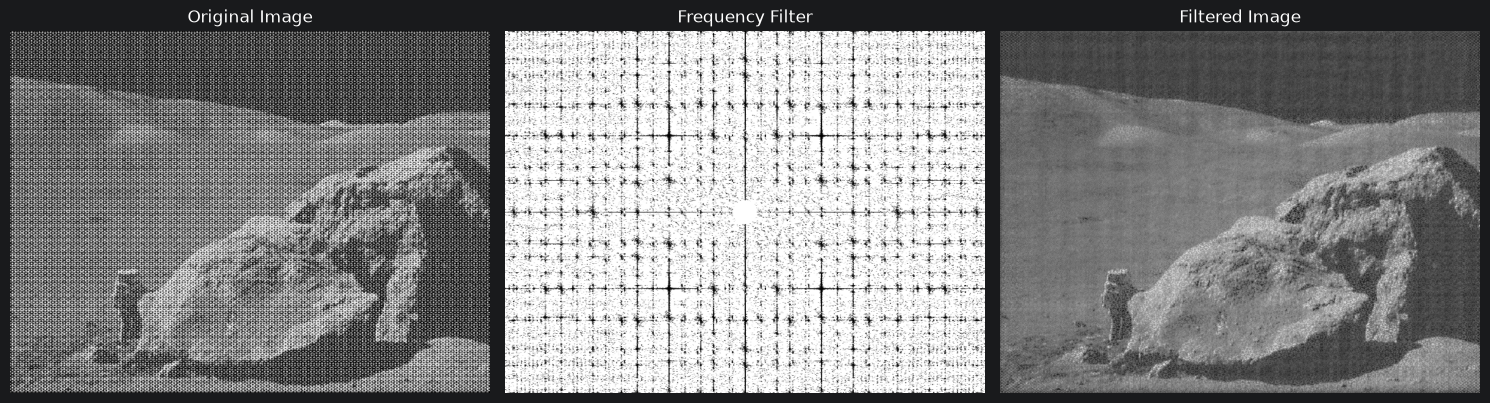

In [29]:

# Прямое преобразование Фурье
fft = np.fft.fftshift(np.fft.fft2(img.astype(np.float32)))

magnitude = np.abs(fft)
log_spectrum = np.log1p(magnitude)


background = cv.GaussianBlur(log_spectrum, (0, 0), 8)


peak_strength = log_spectrum - background
mask = np.exp(-2.0 * np.maximum(peak_strength - 0.6, 0))

rows, cols = img.shape
cy, cx = rows // 2, cols // 2

yy, xx = np.indices(img.shape)


mask = np.minimum(
    mask,
    mask[(-yy) % rows, (-xx) % cols]
)


distance = np.sqrt((xx - cx)**2 + (yy - cy)**2)
mask[distance < 20] = 1


filtered_fft = fft * mask

filtered_img = np.fft.ifft2(np.fft.ifftshift(filtered_fft))
filtered_img = np.real(filtered_img)
filtered_img = np.clip(filtered_img, 0, 255).astype(np.uint8)

plt.figure(figsize=(15, 5))

plt.subplot(131)
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title('Original Image')
plt.axis('off')

plt.subplot(132)
plt.imshow(mask, cmap='gray', vmin=0, vmax=1)
plt.title('Frequency Filter')
plt.axis('off')

plt.subplot(133)
plt.imshow(filtered_img, cmap='gray', vmin=0, vmax=255)
plt.title('Filtered Image')
plt.axis('off')

plt.tight_layout()
plt.show()
